# Finding Heavy Traffic Indicators on the I-94
In this notebook, we will explore UCI's dataset for hourly Interstate 94 Westbound traffic volume. We will focus on looking at how weather and datetime are correlated with heavy traffic. Note that the data only accounts for I-94 Westbound traffic and not Eastbound traffic, so findings should not be generalized for all I-94 traffic.

## Reading the CSV

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# https://www.dataquest.io/projects/guided-project-a-finding-heavy-traffic-indicators-on-i-94/
# https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume
df = pd.read_csv('./datasets/Metro_Interstate_Traffic_Volume.csv')
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [2]:
df.tail()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
48199,NaN,283.45,0.0,0.0,75,Clouds,broken clouds,2018-09-30 19:00:00,3543
48200,NaN,282.76,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 20:00:00,2781
48201,NaN,282.73,0.0,0.0,90,Thunderstorm,proximity thunderstorm,2018-09-30 21:00:00,2159
48202,NaN,282.09,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 22:00:00,1450
48203,NaN,282.12,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 23:00:00,954


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 5.0 MB


We can see there are only a few non-null entries in the holiday column, which makes sense because most days are not holidays. None of the other columns have null values present. Each row in the dataset accounts for an hour, from 2012-10-02 09:00:00 to 2018-09-30 23:00:00.

## Traffic Volume Distribution

Text(0, 0.5, 'Frequency')

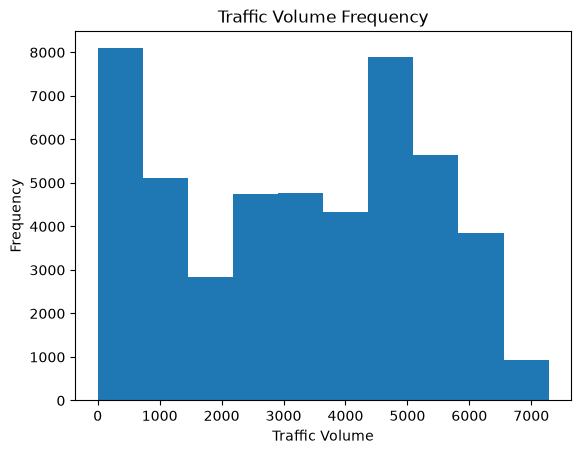

In [4]:
fig, ax = plt.subplots()

ax.hist(df['traffic_volume'])
ax.set_title('Traffic Volume Frequency')
ax.set_xlabel('Traffic Volume')
ax.set_ylabel('Frequency')

In [5]:
df['traffic_volume'].describe()

count    48204.000000
mean      3259.818355
std       1986.860670
min          0.000000
25%       1193.000000
50%       3380.000000
75%       4933.000000
max       7280.000000
Name: traffic_volume, dtype: float64

The traffic volume varies widely, from 0 to 7280 cars passing the checkpoint hourly. Around 25% of the time, there are less than 1193 cars and another 25% of the time there are over 4933 cars, and there is a large standard deviation of 1986 cars from the mean of 3259 cars. Let's hypothesize that the time of day is responsible for this variation in traffic volume and there are less people driving at night.

## Day vs. Night
We can roughly divide the data into day and night subsets with the cutoff at 7am and 7pm. While this is not perfect, it can give us a rough idea of how traffic changes when the sun rises or sets.

In [6]:
# change col from str to dt format to extract hour
df['date_time'] = pd.to_datetime(df['date_time'])
df['hour'] = df['date_time'].dt.hour

day = df[(df['hour'] >= 7) & (df['hour'] <= 18)]
night = df[(df['hour'] < 7) | (df['hour'] > 18)]

(0.0, 8000.0)

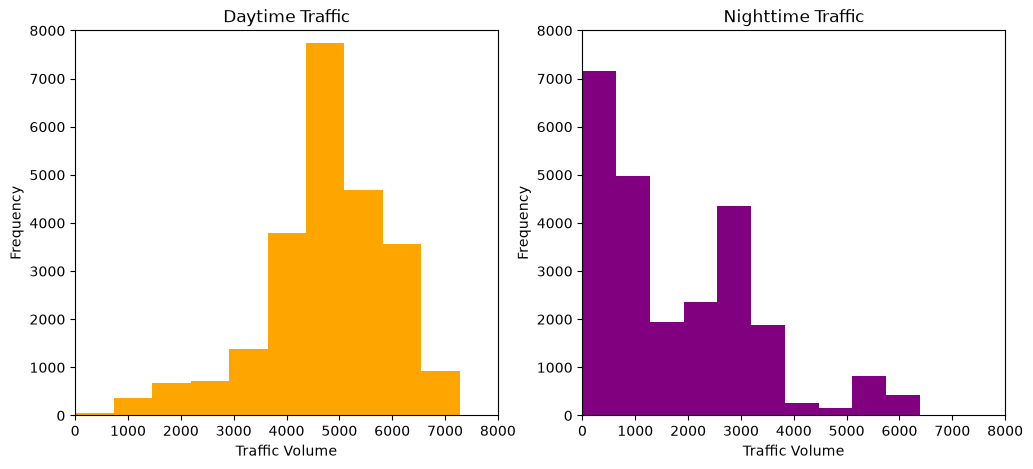

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].hist(day['traffic_volume'], color='orange')
ax[0].set_title('Daytime Traffic')
ax[0].set_xlabel('Traffic Volume')
ax[0].set_ylabel('Frequency')
ax[0].set_xlim(0, 8000) # make axes the same
ax[0].set_ylim(0, 8000)

ax[1].hist(night['traffic_volume'], color='purple')
ax[1].set_title('Nighttime Traffic')
ax[1].set_xlabel('Traffic Volume')
ax[1].set_ylabel('Frequency')
ax[1].set_xlim(0, 8000)
ax[1].set_ylim(0, 8000)

In [8]:
print(day['traffic_volume'].describe(), night['traffic_volume'].describe())

count    23877.000000
mean      4762.047452
std       1174.546482
min          0.000000
25%       4252.000000
50%       4820.000000
75%       5559.000000
max       7280.000000
Name: traffic_volume, dtype: float64 count    24327.000000
mean      1785.377441
std       1441.951197
min          0.000000
25%        530.000000
50%       1287.000000
75%       2819.000000
max       6386.000000
Name: traffic_volume, dtype: float64


These histograms confirm our earlier hypothesis that there is less traffic at night than during the day. 75% of the time there are more than 4252 cars on the I-94 during the day, whereas 75% of the time there are less than 2819 cars at night. Since we are looking for indicators of high traffic, we will focus on the daytime data.

## Time Indicators
Let's look at traffic by month, day of week, and time of day.

In [9]:
day['month'] = day['date_time'].dt.month
monthly_avg = day.groupby('month')['traffic_volume'].mean()
monthly_avg

month
1     4495.613727
2     4711.198394
3     4889.409560
4     4906.894305
5     4911.121609
6     4898.019566
7     4595.035744
8     4928.302035
9     4870.783145
10    4921.234922
11    4704.094319
12    4374.834566
Name: traffic_volume, dtype: float64

Text(0, 0.5, 'Average Volume')

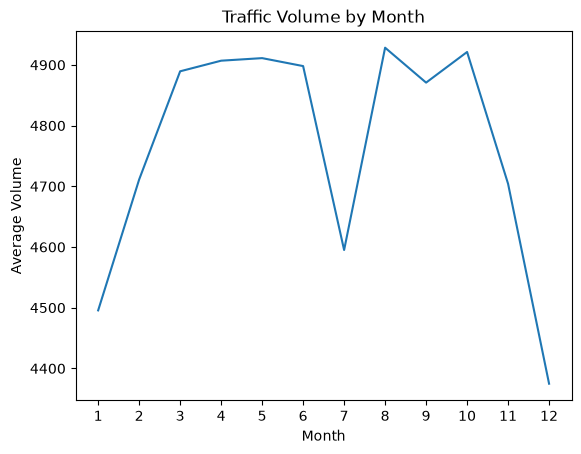

In [10]:
fig, ax = plt.subplots()
ax.plot(monthly_avg)
ax.set_title('Traffic Volume by Month')
ax.set_xlabel('Month')
ax.set_xticks(range(1, 13))
ax.set_ylabel('Average Volume')

Traffic volume is low during the winter months, but higher from the spring to fall with the exception of July. Let's take a closer look at what happened in July.

In [11]:
day['year'] = day['date_time'].dt.year
july_only = day[day['month'] == 7].groupby('year')['traffic_volume'].mean()
july_only

year
2013    4914.354054
2014    4871.598240
2015    4613.146226
2016    3924.923645
2017    4734.120301
2018    4586.899543
Name: traffic_volume, dtype: float64

Text(0, 0.5, 'Average Volume')

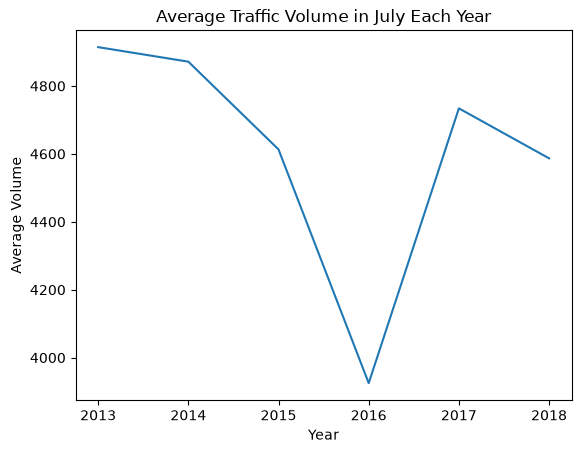

In [12]:
fig, ax = plt.subplots()
ax.plot(july_only)
ax.set_title('Average Traffic Volume in July Each Year')
ax.set_xlabel('Year')
ax.set_ylabel('Average Volume')

It appears traffic in July is typically pretty high, similar to the other warmer months. However, there is a dip in 2016 which could indicate road work or some other issue.

In [13]:
day['dayofweek'] = day['date_time'].dt.dayofweek
weekday_avg = day.groupby('dayofweek')['traffic_volume'].mean()
weekday_avg

dayofweek
0    4893.551286
1    5189.004782
2    5284.454282
3    5311.303730
4    5291.600829
5    3927.249558
6    3436.541789
Name: traffic_volume, dtype: float64

Text(0, 0.5, 'Average Volume')

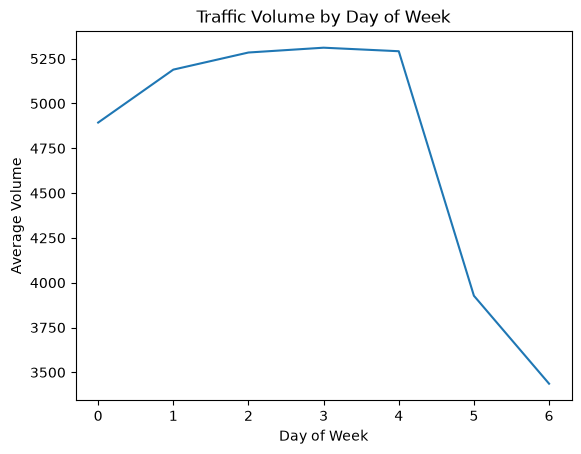

In [14]:
fig, ax = plt.subplots()
ax.plot(weekday_avg)
ax.set_title('Traffic Volume by Day of Week')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Average Volume')

Traffic is much higher on typical working days (Monday-Friday) than weekends, with usually over 5000 cars on average (with the exception of Monday). Traffic is lighter on the weekends, with less than 4000 cars.

In [15]:
workdays = day[day['dayofweek'] < 5]
weekends = day[day['dayofweek'] >= 5]

workday_avg = workdays.groupby('hour')['traffic_volume'].mean()
weekend_avg = weekends.groupby('hour')['traffic_volume'].mean()

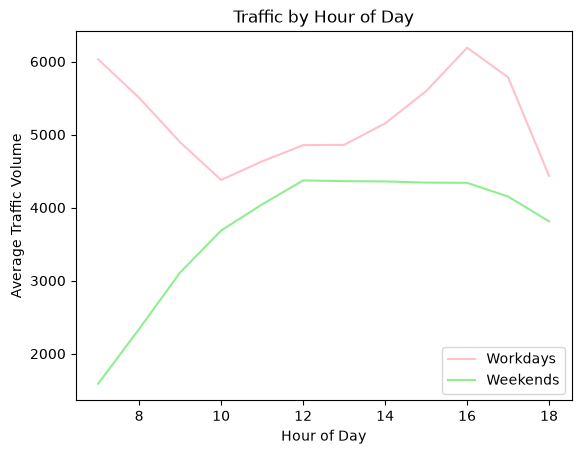

In [16]:
fig, ax = plt.subplots()

ax.plot(workday_avg, color='pink', label='Workdays')
ax.plot(weekend_avg, color='lightgreen', label='Weekends')
ax.set_title('Traffic by Hour of Day')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Average Traffic Volume')
ax.legend()

To avoid the lower traffic volume on weekends skewing the data, workdays and weekends have been plotted separately. The workday traffic peaks at over 6000 cars around 7am and 4pm, which is around rush hour when most people travel to or from work. 

<Axes: xlabel='hour', ylabel='dayofweek'>

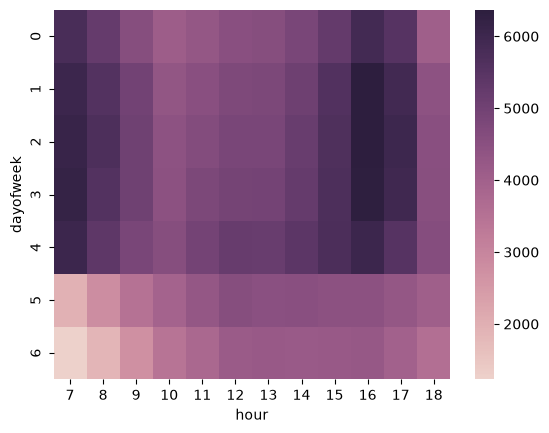

In [73]:
import seaborn as sns

day_and_hour = day.pivot_table(index="dayofweek", columns="hour", values="traffic_volume", aggfunc='mean')
sns.heatmap(day_and_hour, cmap=sns.cubehelix_palette(as_cmap=True))

The heatmap shows that the heaviest traffic is around 7am and 4pm from Tuesday to Thursday. It's possible that Monday and Friday has less traffic due to remote workers or people taking days adjacent to the weekend off. There is the least traffic around 7-8am on Sunday, which could be from people sleeping in on the weekend.

## Weather Indicators

In [22]:
day.info()

<class 'pandas.DataFrame'>
Index: 23877 entries, 0 to 48198
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              0 non-null      str           
 1   temp                 23877 non-null  float64       
 2   rain_1h              23877 non-null  float64       
 3   snow_1h              23877 non-null  float64       
 4   clouds_all           23877 non-null  int64         
 5   weather_main         23877 non-null  str           
 6   weather_description  23877 non-null  str           
 7   date_time            23877 non-null  datetime64[us]
 8   traffic_volume       23877 non-null  int64         
 9   hour                 23877 non-null  int32         
 10  month                23877 non-null  int32         
 11  year                 23877 non-null  int32         
 12  dayofweek            23877 non-null  int32         
dtypes: datetime64[us](1), float64(3), int32(4), int

In [27]:
day.corr(numeric_only=True)['traffic_volume'] # corr func doesn't work with str so select numeric only

temp              0.128317
rain_1h           0.003697
snow_1h           0.001265
clouds_all       -0.032932
traffic_volume    1.000000
hour              0.172704
month            -0.022337
year             -0.003557
dayofweek        -0.416453
Name: traffic_volume, dtype: float64

Temperature shows the strongest correlation among all the weather indicators, at almost +0.13.

Text(0, 0.5, 'Temperature')

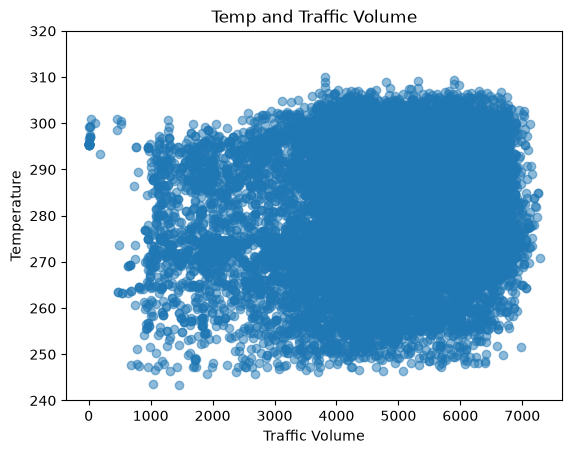

In [34]:
fig, ax = plt.subplots()
ax.scatter(day['traffic_volume'], day['temp'], alpha=0.5)
plt.ylim(240, 320) # don't show outliers
ax.set_title('Temp and Traffic Volume')
ax.set_xlabel('Traffic Volume')
ax.set_ylabel('Temperature')

There are no clearly visible trends in the scatter plot, so temperature does not appear to be a solid indicator of traffic volume.

Text(0, 0.5, 'Main Weather')

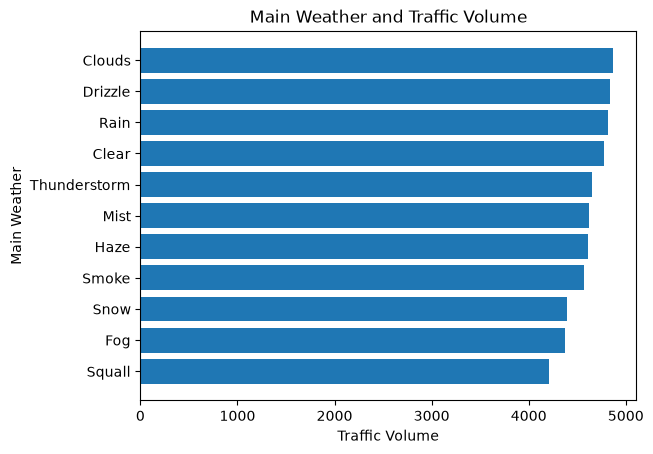

In [46]:
weather_main_and_traffic = day.groupby('weather_main')['traffic_volume'].mean().sort_values()

fig, ax = plt.subplots()
ax.barh(weather_main_and_traffic.index, weather_main_and_traffic.values)
ax.set_title('Main Weather and Traffic Volume')
ax.set_xlabel('Traffic Volume')
ax.set_ylabel('Main Weather')

The top 3 weather conditions with the highest traffic volume are clouds, drizzle, and rain. Surprisingly, clear weather ranks 4th on the list. The 3 weather conditions with the lowest traffic volume are snow, fog, and squall. The range in traffic is <1k cars, so the weather doesn't impact traffic volume by much.

Text(0, 0.5, 'Main Description')

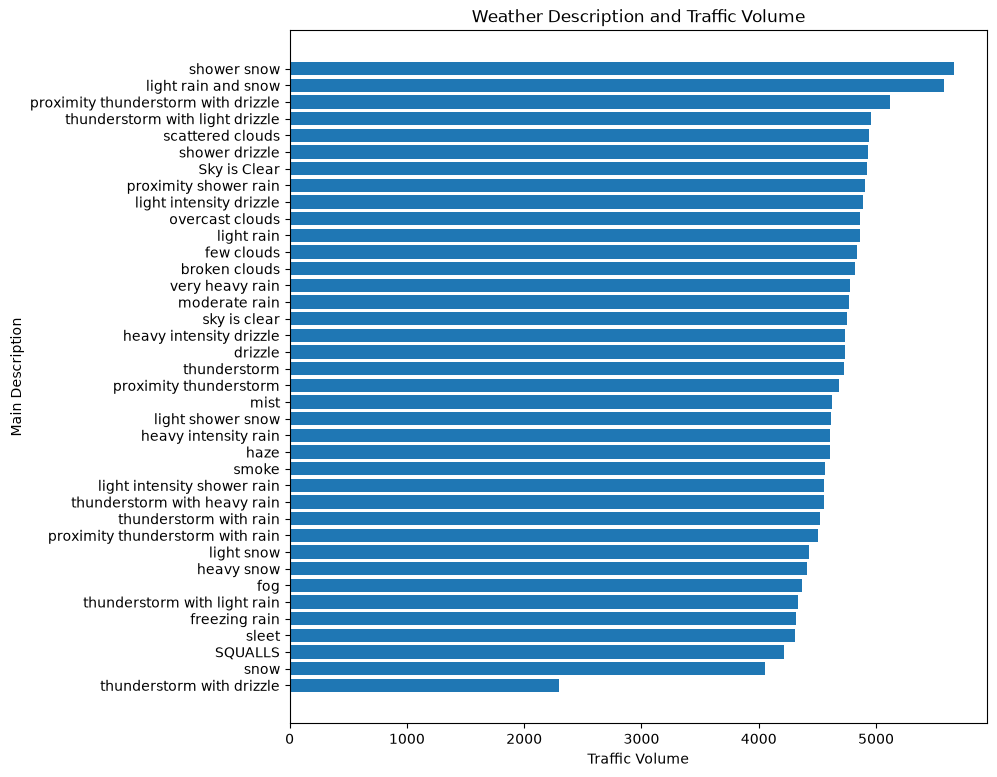

In [55]:
weather_description_and_traffic = day.groupby('weather_description')['traffic_volume'].mean().sort_values()

fig, ax = plt.subplots(figsize=(9,9))
ax.barh(weather_description_and_traffic.index, weather_description_and_traffic.values)
ax.set_title('Weather Description and Traffic Volume')
ax.set_xlabel('Traffic Volume')
ax.set_ylabel('Main Description')

From the more detailed weather breakdown, the top 3 conditions with traffic volume of over 5000 cars/hour is shower snow, light rain and snow, and proximity thunderstorm with drizzle. The lowest category is thunderstorm with drizzle. 

## Conclusion
In conclusion, the indicators for heavy traffic are:
- Warm months (March - October)
- Working days (Monday - Friday)
- Rush hours (7am and 4pm)
- Weather conditions (shower snow, light rain and snow, proximity thunderstorm with drizzle)